<a href="https://colab.research.google.com/github/AndrewWHans/Data-Fest-2026/blob/main/Andrew's_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import polars as pl
import matplotlib.pyplot as plt

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy.ndimage import gaussian_filter1d
from google.colab import drive

drive.mount("/content/drive", force_remount=True)
path = "/content/drive/MyDrive/merged_data_encounterMain.parquet"

df = pl.read_parquet(path)

# ── Filter to respiratory encounters only ────────────────────────────────────
resp_df = df.filter(
    pl.col("DepartmentSpecialty").str.contains(
        r"(?i)pulmon|respiratory|lung|chest|thorac"
    )
)

# ── Flag ED encounters ───────────────────────────────────────────────────────
resp_df = resp_df.with_columns(
    pl.col("PatientClass")
    .str.contains(r"(?i)emergency|ED")
    .cast(pl.Int8)
    .alias("is_ed")
)

# ── Keep races with enough volume ────────────────────────────────────────────
keep_races = [
    "White",
    "Black or African American",
    "Some Other Race",
    "Two or More Races",
]
resp_df = resp_df.filter(pl.col("PatientRace").is_in(keep_races))

# ── Compute per age×race ED rate ─────────────────────────────────────────────
age_race = (
    resp_df.filter(pl.col("Age").is_not_null())
    .with_columns(pl.col("Age").cast(pl.Int32))
    .filter((pl.col("Age") >= 0) & (pl.col("Age") <= 85))
    .group_by(["Age", "PatientRace"])
    .agg(
        pl.len().alias("total"),
        pl.col("is_ed").sum().alias("ed_count"),
    )
    .with_columns(
        (pl.col("ed_count") / pl.col("total") * 100).alias("ed_rate")
    )
    .sort(["PatientRace", "Age"])
)

# ── Plot ─────────────────────────────────────────────────────────────────────
color_map = {
    "White": "#4472C4",
    "Black or African American": "#C00000",
    "Some Other Race": "#70AD47",
    "Two or More Races": "#ED7D31",
}

fig, ax = plt.subplots(figsize=(14, 7))
ages = list(range(0, 86))

for race, color in color_map.items():
    subset = age_race.filter(pl.col("PatientRace") == race)
    age_vals = subset["Age"].to_list()
    rate_vals = subset["ed_rate"].to_list()

    # Interpolate to full age range
    rate_interp = np.interp(ages, age_vals, rate_vals)
    smoothed = gaussian_filter1d(rate_interp, sigma=2)

    # Confidence band (±1 SE approximation from total counts)
    total_interp = np.interp(
        ages,
        age_vals,
        subset["total"].to_list(),
    )
    se = np.sqrt(
        (smoothed / 100) * (1 - smoothed / 100) / np.maximum(total_interp, 1)
    ) * 100

    ax.plot(ages, smoothed, color=color, linewidth=2, label=race)
    ax.fill_between(
        ages,
        smoothed - se,
        smoothed + se,
        color=color,
        alpha=0.15,
    )

# Policy threshold lines
ax.axvline(26, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.axvline(65, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.text(26.5, 92, "ACA age-out\n(age 26)", fontsize=8, color="gray")
ax.text(65.5, 92, "Medicare\n(age 65)", fontsize=8, color="gray")

ax.set_xlabel("Patient Age", fontsize=12)
ax.set_ylabel("ED Visit Rate (%)", fontsize=12)
ax.set_title(
    "Emergency Department Reliance for Respiratory Encounters by Race\nStormont Vail, 2022–2025",
    fontsize=13,
    fontweight="bold",
)
ax.set_ylim(15, 100)
ax.legend(loc="upper right", fontsize=10)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("fig01_ed_reliance_by_age_race.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig01_ed_reliance_by_age_race.png")


Mounted at /content/drive


FileNotFoundError: No such file or directory (os error 2): /content/drive/MyDrive/merged_data_encounterMain.parquet

This error occurred with the following context stack:
	[1] 'parquet scan'
	[2] 'sink'


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

base = '/content/drive/Shareddrives'
if os.path.exists(base):
    print(os.listdir(base))
else:
    base = '/content/drive/MyDrive'
    print(os.listdir(base))

Mounted at /content/drive
['DataFest 2026']


In [ ]:
df_merged = pl.read_parquet('/content/merged_data_encounterMain.parquet')
print(df_merged.shape)
print(df_merged.head())

FileNotFoundError: No such file or directory (os error 2): /content/merged_data_encounterMain.parquet

This error occurred with the following context stack:
	[1] 'parquet scan'
	[2] 'sink'


In [ ]:
# Schema and nulls
print(df_merged.schema)
print("\nNull counts:")
print(df_merged.null_count())

Schema({'Date': String, 'AdmissionInstant': String, 'AdmitYear': Float64, 'AdmitMonth': Float64, 'AdmitDay': Float64, 'AdmitHour': Float64, 'AdmitMinute': Float64, 'AdmissionSource': String, 'AdmissionType': String, 'DischargeInstant': String, 'DischargeYear': Float64, 'DischargeMonth': Float64, 'DischargeDay': Float64, 'DischargeHour': Float64, 'DischargeMinute': Float64, 'EncounterKey': Int64, 'PatientDurableKey': Int64, 'Type': String, 'VisitType': String, 'VisitTypeDescription': String, 'ProviderDurableKey': Int64, 'AttendingProviderDurableKey': Int64, 'DischargeProviderDurableKey': Int64, 'DepartmentKey': Int64, 'PrimaryDiagnosisKey': Int64, 'IsEdVisit': Int64, 'IsHospitalAdmission': Int64, 'IsHospitalOutpatientVisit': Int64, 'IsInpatientAdmission': Int64, 'IsObservation': Int64, 'IsOutpatientFaceToFaceVisit': Int64, 'DiagnosisKey': Float64, 'GroupName': String, 'GroupCode': String, 'DiagnosisName': String, 'DiagnosisValue': String, 'CensusBlockGroupFipsCode': String, 'DurableKey'

In [ ]:
for col in ['AdmissionSource', 'AdmissionType', 'DepartmentSpecialty', 'DepartmentType']:
    counts = df_merged[col].value_counts().sort('count', descending=True)
    print(f"\n=== {col} ===")
    print(counts)


=== AdmissionSource ===
shape: (47, 2)
┌─────────────────────────────────┬─────────┐
│ AdmissionSource                 ┆ count   │
│ ---                             ┆ ---     │
│ str                             ┆ u32     │
╞═════════════════════════════════╪═════════╡
│ *Not Applicable                 ┆ 6554150 │
│ Clinic or Physician's Office    ┆ 446615  │
│ Non-Health Care Facility Point… ┆ 329476  │
│ Clinic/Physician Referral       ┆ 243193  │
│ Home                            ┆ 72274   │
│ …                               ┆ …       │
│ Hospice                         ┆ 1       │
│ Hospice at Home                 ┆ 1       │
│ Transfer from another Home Hea… ┆ 1       │
│ Hospice at SNF                  ┆ 1       │
│ TRANSFER FROM SDU TO ACUTE-MED… ┆ 1       │
└─────────────────────────────────┴─────────┘

=== AdmissionType ===
shape: (9, 2)
┌───────────────────────────┬─────────┐
│ AdmissionType             ┆ count   │
│ ---                       ┆ ---     │
│ str                

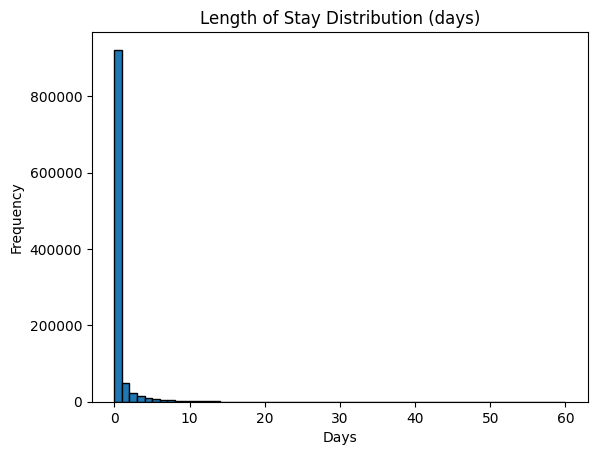

In [ ]:
df_los = df_merged.with_columns([
    (pl.col('DischargeYear') * 365 + pl.col('DischargeMonth') * 30 + pl.col('DischargeDay')
     - pl.col('AdmitYear') * 365 - pl.col('AdmitMonth') * 30 - pl.col('AdmitDay'))
    .alias('LOS_days')
])

los = df_los['LOS_days'].drop_nulls().clip(0, 60).to_list()
plt.hist(los, bins=60, edgecolor='black')
plt.title('Length of Stay Distribution (days)')
plt.xlabel('Days'); plt.ylabel('Frequency')
plt.show()

In [ ]:
df_merged = pl.read_parquet('/content/merged_data_encounterMain.parquet')

postal_counts = (
    df_merged
    .group_by('PostalCode')
    .agg(pl.len().alias('count'))
    .sort('count', descending=True)
    .head(20)
)
print(postal_counts)

plt.barh(postal_counts['PostalCode'].cast(str).to_list(), postal_counts['count'].to_list())
plt.title('Top 20 Postal Codes by Admissions')
plt.tight_layout(); plt.show()

Under here, looking for trends in pregnancy analysis

In [ ]:
df_merged = pl.read_parquet('/content/merged_data_encounterMain.parquet')

ob_df = df_merged.filter(
    pl.col('DepartmentSpecialty').str.contains('(?i)obstetric|labor|delivery|maternal|prenatal')
    | pl.col('DepartmentType').str.contains('(?i)L&D|OB')
)

del df_merged

print(f"OB encounters: {ob_df.shape[0]:,}")
print(ob_df['DepartmentSpecialty'].value_counts().sort('count', descending=True))
print(ob_df['AdmissionType'].value_counts().sort('count', descending=True))

OB encounters: 175,163
shape: (4, 2)
┌─────────────────────────────┬────────┐
│ DepartmentSpecialty         ┆ count  │
│ ---                         ┆ ---    │
│ str                         ┆ u32    │
╞═════════════════════════════╪════════╡
│ Obstetrics and Gynecology   ┆ 114405 │
│ Maternal and Fetal Medicine ┆ 27969  │
│ Obstetrics                  ┆ 27738  │
│ *Unspecified                ┆ 5051   │
└─────────────────────────────┴────────┘
shape: (7, 2)
┌───────────────────────────┬────────┐
│ AdmissionType             ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ *Not Applicable           ┆ 146074 │
│ Elective                  ┆ 21242  │
│ Newborn                   ┆ 5041   │
│ Emergency                 ┆ 1399   │
│ Urgent                    ┆ 1394   │
│ Trauma Center             ┆ 8      │
│ Information Not Available ┆ 5      │
└───────────────────────────┴────────┘


shape: (4, 2)
┌───────────┬───────┐
│ AdmitYear ┆ count │
│ ---       ┆ ---   │
│ i32       ┆ u32   │
╞═══════════╪═══════╡
│ 2022      ┆ 4843  │
│ 2023      ┆ 5930  │
│ 2024      ┆ 6397  │
│ 2025      ┆ 7681  │
└───────────┴───────┘


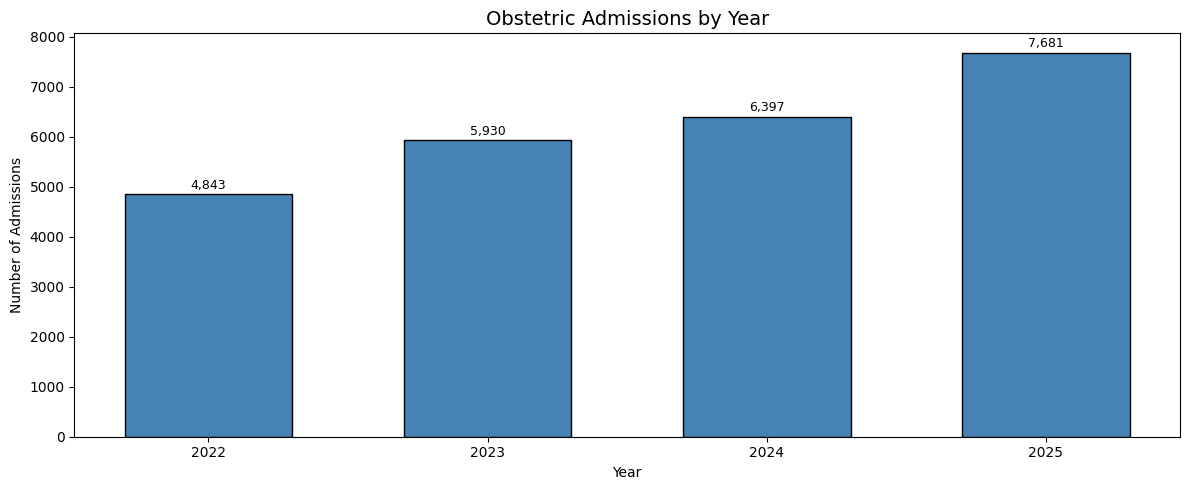

In [ ]:
ob_yearly = (
    ob_df
    .filter(pl.col('AdmitYear').is_not_null())
    .with_columns(pl.col('AdmitYear').cast(pl.Int32).alias('AdmitYear'))
    .group_by('AdmitYear')
    .agg(pl.len().alias('count'))
    .sort('AdmitYear')
)

print(ob_yearly)  # Check what years exist

years = ob_yearly['AdmitYear'].to_list()
counts = ob_yearly['count'].to_list()

plt.figure(figsize=(12, 5))
bars = plt.bar(years, counts, color='steelblue', edgecolor='black', width=0.6)

# Add count labels on top of each bar
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{count:,}', ha='center', va='bottom', fontsize=9)

plt.title('Obstetric Admissions by Year', fontsize=14)
plt.xlabel('Year'); plt.ylabel('Number of Admissions')
plt.xticks(years)
plt.tight_layout()
plt.show()

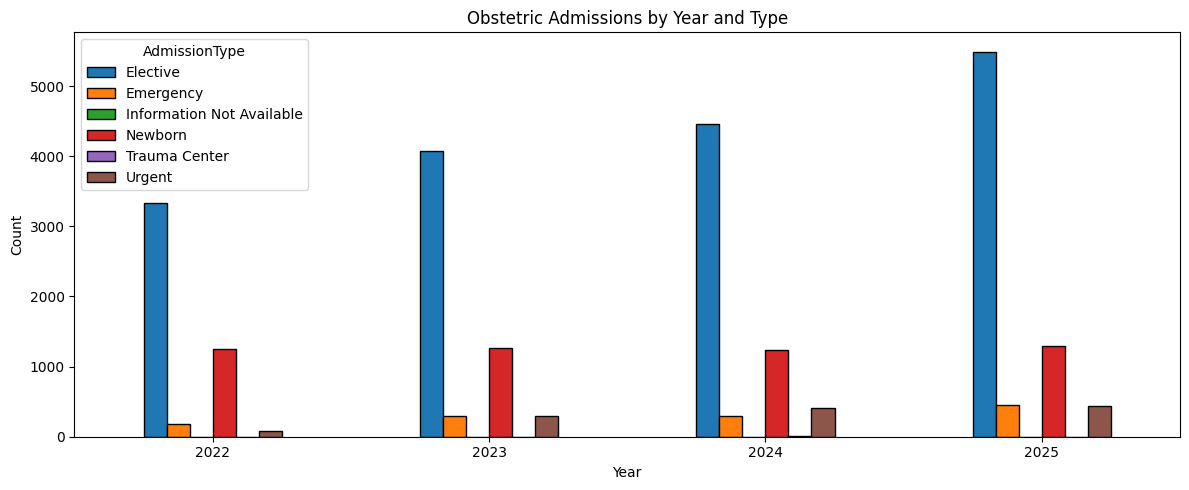

In [ ]:
# Is the INCREASE driven by emergency admissions growing faster than elective?
ob_type_year = (
    ob_df
    .filter(pl.col('AdmitYear').is_not_null() & pl.col('AdmissionType').is_not_null())
    .with_columns(pl.col('AdmitYear').cast(pl.Int32))
    .group_by(['AdmitYear', 'AdmissionType'])
    .agg(pl.len().alias('count'))
    .sort(['AdmitYear', 'AdmissionType'])
)

# Pivot for grouped bar chart
import pandas as pd
ob_type_pd = ob_type_year.to_pandas()
ob_pivot = ob_type_pd.pivot(index='AdmitYear', columns='AdmissionType', values='count').fillna(0)

ob_pivot.plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Obstetric Admissions by Year and Type')
plt.xlabel('Year'); plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

# After adding the shortcut, this path will work
path = '/content/drive/MyDrive/merged_data_encounterMain.parquet'

df_merged = pl.read_parquet(path)

ob_df = df_merged.filter(
    pl.col('DepartmentSpecialty').str.contains('(?i)obstetric|labor|delivery|maternal|prenatal')
)
resp_df = df_merged.filter(
    pl.col('DepartmentSpecialty').str.contains('(?i)pulmon|respiratory|lung|chest|thorac')
)
del df_merged

print("OB rows:", ob_df.shape[0])
print("Resp rows:", resp_df.shape[0])

resp_yearly = (
    resp_df
    .filter(pl.col('AdmitYear').is_not_null())
    .with_columns(pl.col('AdmitYear').cast(pl.Int32))
    .group_by('AdmitYear')
    .agg(pl.len().alias('count'))
    .sort('AdmitYear')
)
print(resp_yearly)

Mounted at /content/drive
OB rows: 170112
Resp rows: 64783
shape: (4, 2)
┌───────────┬───────┐
│ AdmitYear ┆ count │
│ ---       ┆ ---   │
│ i32       ┆ u32   │
╞═══════════╪═══════╡
│ 2022      ┆ 347   │
│ 2023      ┆ 1415  │
│ 2024      ┆ 1547  │
│ 2025      ┆ 1517  │
└───────────┴───────┘


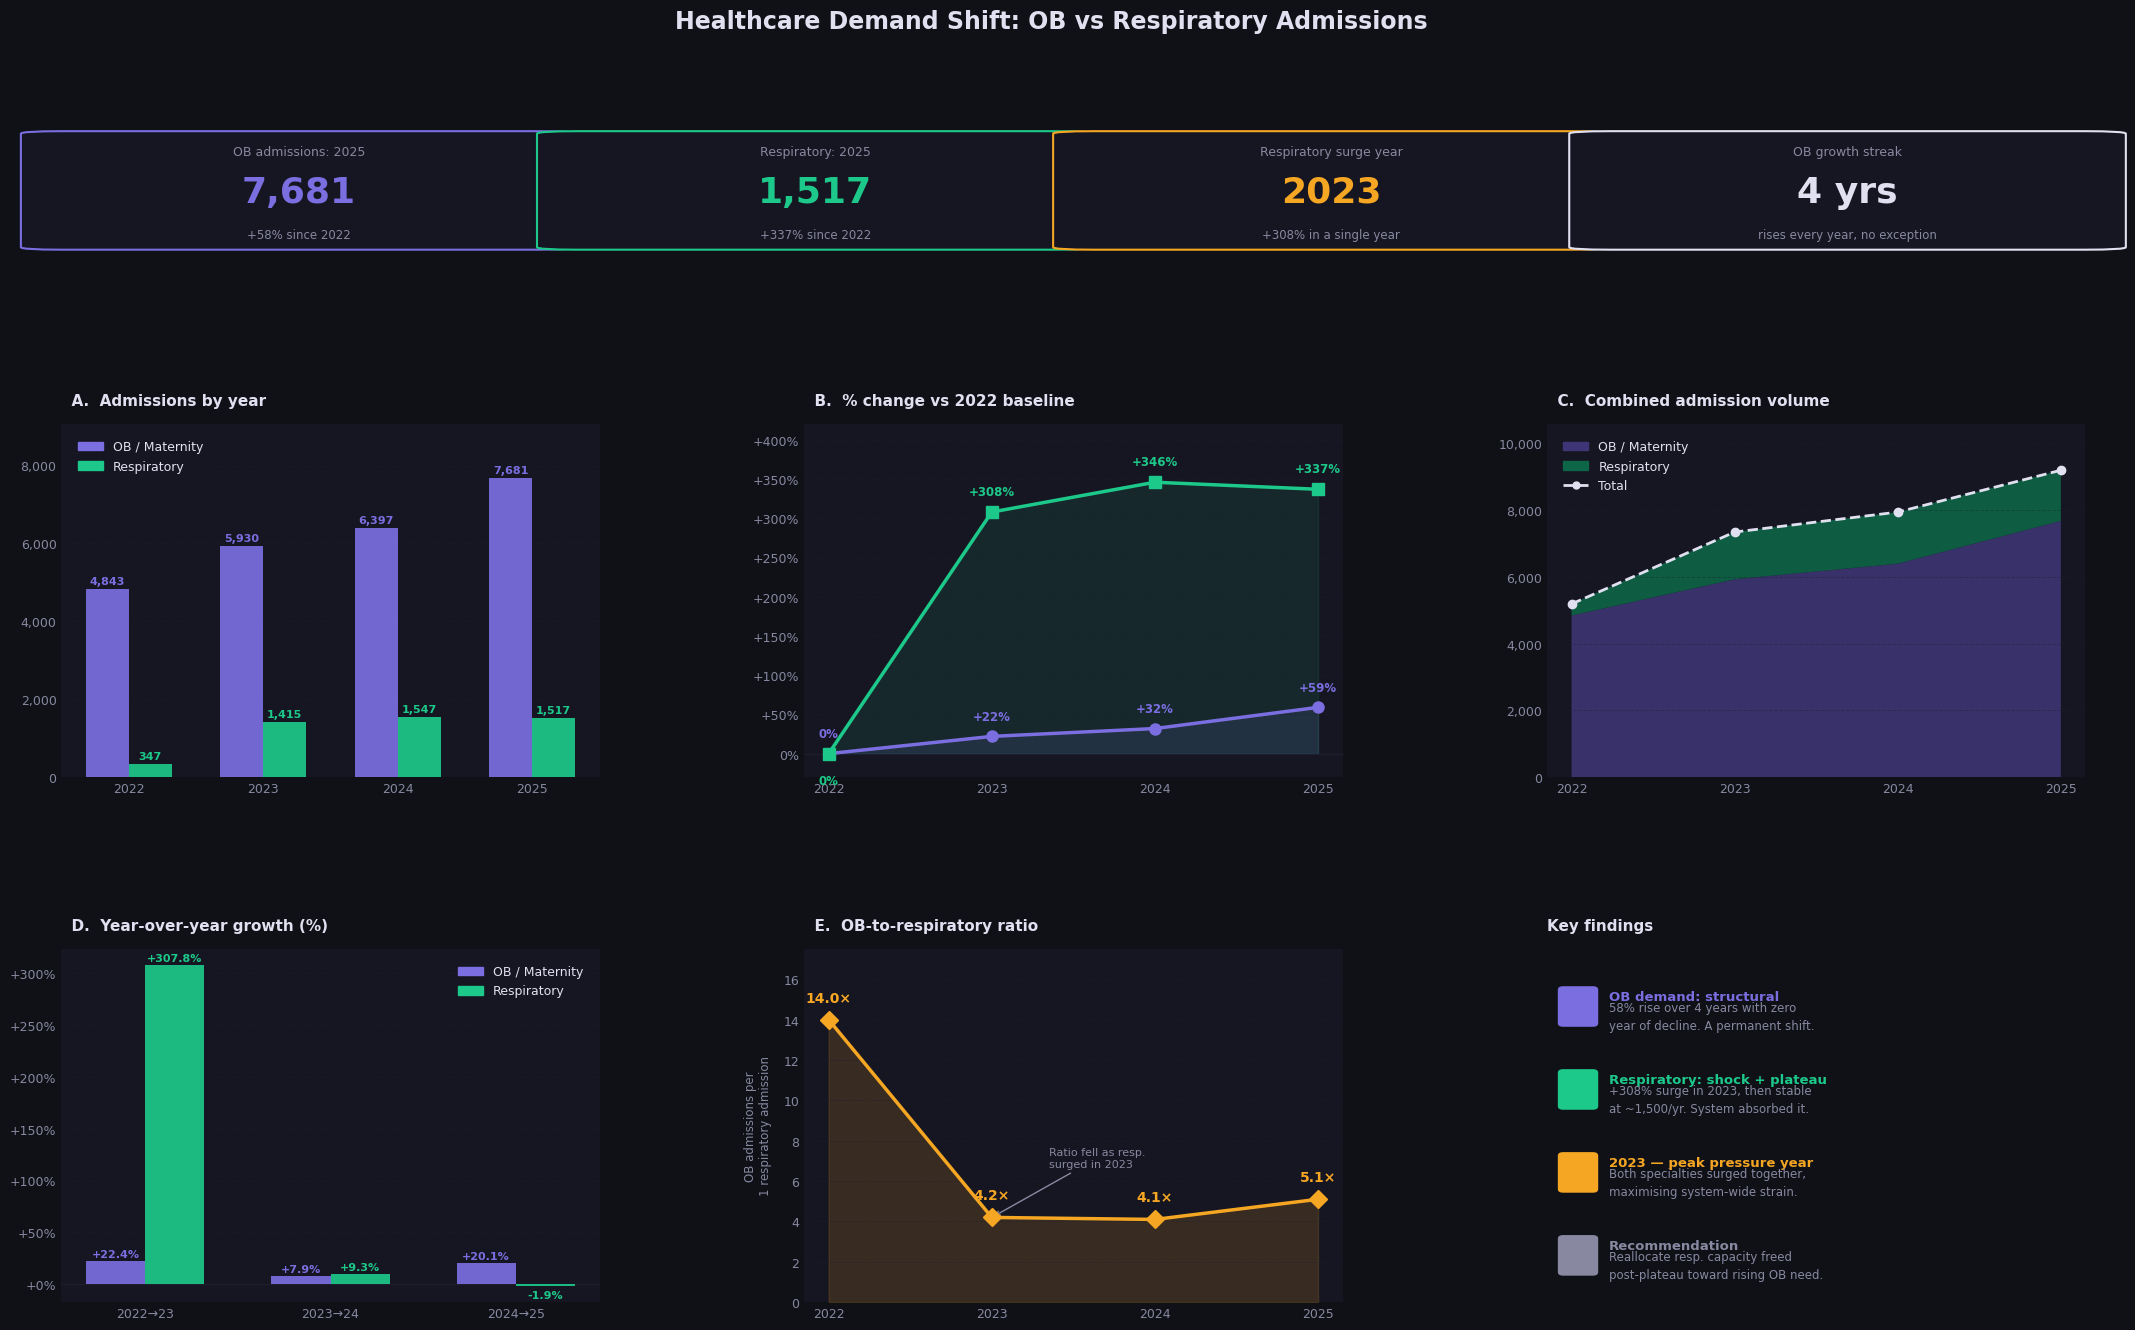

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np

# ── Data ──────────────────────────────────────────────────
years = [2022, 2023, 2024, 2025]
ob    = [4843, 5930, 6397, 7681]
resp  = [347,  1415, 1547, 1517]

ob_pct   = [0] + [round((ob[i]/ob[0]-1)*100)   for i in range(1,4)]
resp_pct = [0] + [round((resp[i]/resp[0]-1)*100) for i in range(1,4)]
ob_yoy   = [round((ob[i+1]/ob[i]-1)*100,1)   for i in range(3)]
resp_yoy = [round((resp[i+1]/resp[i]-1)*100,1) for i in range(3)]
ratio    = [round(o/r,1) for o,r in zip(ob,resp)]

# ── Colors ────────────────────────────────────────────────
BG        = '#0F1117'
CARD      = '#161622'
OB_COL    = '#7B6EE0'
OB_LIGHT  = '#3D3575'
RESP_COL  = '#1DC98A'
RESP_LIGHT= '#0D6647'
AMBER     = '#F5A623'
WHITE     = '#E0E0F0'
MUTED     = '#8888A0'
GRID      = '#1E1E2E'

plt.rcParams.update({
    'figure.facecolor':   BG,
    'axes.facecolor':     CARD,
    'axes.edgecolor':     GRID,
    'axes.labelcolor':    MUTED,
    'xtick.color':        MUTED,
    'ytick.color':        MUTED,
    'xtick.labelsize':    9,
    'ytick.labelsize':    9,
    'grid.color':         GRID,
    'grid.linewidth':     0.7,
    'text.color':         WHITE,
    'font.family':        'DejaVu Sans',
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'axes.spines.left':   False,
    'axes.spines.bottom': False,
})

def style(ax, title):
    ax.set_facecolor(CARD)
    ax.set_title(f'  {title}', fontsize=11, fontweight='bold',
                 color=WHITE, pad=14, loc='left')
    ax.tick_params(labelsize=9, length=0)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    for sp in ax.spines.values():
        sp.set_visible(False)

# ── Figure ────────────────────────────────────────────────
fig = plt.figure(figsize=(22, 14), facecolor=BG)

fig.text(0.5, 0.97,
         'Healthcare Demand Shift: OB vs Respiratory Admissions',
         ha='center', fontsize=17, fontweight='bold', color=WHITE)
fig.text(0.5, 0.945,
         '',
         ha='center', fontsize=10, color=MUTED)

# ── GridSpec: KPI row + 2 chart rows ──────────────────────
gs = gridspec.GridSpec(
    3, 3,
    figure=fig,
    height_ratios=[1, 2.8, 2.8],
    hspace=0.62,
    wspace=0.38,
    left=0.05, right=0.97,
    top=0.90, bottom=0.06
)

# ── KPI Banner ────────────────────────────────────────────
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.set_facecolor(BG)
ax_kpi.axis('off')

kpis = [
    ('OB admissions: 2025',    '7,681',  '+58% since 2022',     OB_COL),
    ('Respiratory: 2025',      '1,517',  '+337% since 2022',    RESP_COL),
    ('Respiratory surge year',  '2023',   '+308% in a single year', AMBER),
    ('OB growth streak',        '4 yrs',  'rises every year, no exception', WHITE),
]

for i, (label, val, sub, col) in enumerate(kpis):
    x0 = i * 0.255
    rect = mpatches.FancyBboxPatch(
        (x0, 0.04), 0.235, 0.90,
        boxstyle='round,pad=0.02',
        linewidth=1.5, edgecolor=col,
        facecolor=CARD,
        transform=ax_kpi.transAxes, clip_on=False
    )
    ax_kpi.add_patch(rect)
    cx = x0 + 0.1175
    ax_kpi.text(cx, 0.80, label, ha='center', va='center',
                fontsize=9, color=MUTED, transform=ax_kpi.transAxes)
    ax_kpi.text(cx, 0.48, val,   ha='center', va='center',
                fontsize=26, fontweight='bold', color=col,
                transform=ax_kpi.transAxes)
    ax_kpi.text(cx, 0.14, sub,   ha='center', va='center',
                fontsize=8.5, color=MUTED, transform=ax_kpi.transAxes)

# ── A: Grouped bar ────────────────────────────────────────
ax1 = fig.add_subplot(gs[1, 0])
style(ax1, 'A.  Admissions by year')
x = np.arange(4)
w = 0.32
b1 = ax1.bar(x - w/2, ob,   width=w, color=OB_COL,   alpha=0.92, zorder=3)
b2 = ax1.bar(x + w/2, resp, width=w, color=RESP_COL, alpha=0.92, zorder=3)
ax1.set_xticks(x); ax1.set_xticklabels(years)
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax1.set_ylim(0, max(ob)*1.18)

for bar, val in zip(b1, ob):
    ax1.text(bar.get_x()+bar.get_width()/2,
             bar.get_height() + 120,
             f'{val:,}', ha='center', fontsize=8,
             color=OB_COL, fontweight='bold')
for bar, val in zip(b2, resp):
    ax1.text(bar.get_x()+bar.get_width()/2,
             bar.get_height() + 120,
             f'{val:,}', ha='center', fontsize=8,
             color=RESP_COL, fontweight='bold')
ax1.legend(
    handles=[mpatches.Patch(color=OB_COL,   label='OB / Maternity'),
             mpatches.Patch(color=RESP_COL, label='Respiratory')],
    fontsize=9, framealpha=0, labelcolor=WHITE,
    loc='upper left', borderpad=0.8
)

# ── B: % change line ──────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 1])
style(ax2, 'B.  % change vs 2022 baseline')
ax2.plot(years, ob_pct,   'o-', color=OB_COL,   lw=2.5, ms=8, zorder=4)
ax2.plot(years, resp_pct, 's-', color=RESP_COL, lw=2.5, ms=8, zorder=4)
ax2.axhline(0, color=GRID, lw=1)
ax2.fill_between(years, ob_pct,   alpha=0.12, color=OB_COL)
ax2.fill_between(years, resp_pct, alpha=0.10, color=RESP_COL)
ax2.set_xticks(years)
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v,_: f'+{int(v)}%' if v>0 else '0%'))
ax2.set_ylim(-30, 420)

offsets_ob   = [(0,12), (0,12), (0,12), (0,12)]
offsets_resp = [(0,-22),(0,12), (0,12), (0,12)]
for (yr, val), off in zip(zip(years, ob_pct), offsets_ob):
    ax2.annotate(f'+{val}%' if val>0 else '0%',
                 (yr, val), textcoords='offset points',
                 xytext=off, ha='center', fontsize=8.5,
                 color=OB_COL, fontweight='bold')
for (yr, val), off in zip(zip(years, resp_pct), offsets_resp):
    ax2.annotate(f'+{val}%' if val>0 else '0%',
                 (yr, val), textcoords='offset points',
                 xytext=off, ha='center', fontsize=8.5,
                 color=RESP_COL, fontweight='bold')

# ── C: Stacked area ───────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
style(ax3, 'C.  Combined admission volume')
ax3.stackplot(years, ob, resp,
              colors=[OB_LIGHT, RESP_LIGHT], alpha=0.88)
total = [o+r for o,r in zip(ob,resp)]
ax3.plot(years, total, 'o--', color=WHITE,
         lw=2, ms=6, label='Total', zorder=4)
ax3.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax3.set_xticks(years)
ax3.set_ylim(0, max(total)*1.15)
ax3.legend(
    handles=[mpatches.Patch(color=OB_LIGHT,   label='OB / Maternity'),
             mpatches.Patch(color=RESP_LIGHT, label='Respiratory'),
             plt.Line2D([0],[0], color=WHITE,  lw=2,
                        linestyle='--', marker='o', ms=5, label='Total')],
    fontsize=9, framealpha=0, labelcolor=WHITE,
    loc='upper left', borderpad=0.8
)

# ── D: YoY growth bars ────────────────────────────────────
ax4 = fig.add_subplot(gs[2, 0])
style(ax4, 'D.  Year-over-year growth (%)')
xlbls = ['2022→23', '2023→24', '2024→25']
x = np.arange(3)
w = 0.32
b3 = ax4.bar(x - w/2, ob_yoy,   width=w, color=OB_COL,   alpha=0.92, zorder=3)
b4 = ax4.bar(x + w/2, resp_yoy, width=w, color=RESP_COL, alpha=0.92, zorder=3)
ax4.axhline(0, color=GRID, lw=1)
ax4.set_xticks(x); ax4.set_xticklabels(xlbls, fontsize=9)
ax4.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v,_: f'{v:+.0f}%'))

for bar, val in zip(b3, ob_yoy):
    offset = 4 if val >= 0 else -12
    ax4.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+offset,
             f'{val:+.1f}%', ha='center', fontsize=8,
             color=OB_COL, fontweight='bold')
for bar, val in zip(b4, resp_yoy):
    offset = 4 if val >= 0 else -12
    ax4.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+offset,
             f'{val:+.1f}%', ha='center', fontsize=8,
             color=RESP_COL, fontweight='bold')
ax4.legend(
    handles=[mpatches.Patch(color=OB_COL,   label='OB / Maternity'),
             mpatches.Patch(color=RESP_COL, label='Respiratory')],
    fontsize=9, framealpha=0, labelcolor=WHITE,
    loc='upper right', borderpad=0.8
)

# ── E: OB:Resp ratio ──────────────────────────────────────
ax5 = fig.add_subplot(gs[2, 1])
style(ax5, 'E.  OB-to-respiratory ratio')
ax5.plot(years, ratio, 'D-', color=AMBER, lw=2.5, ms=9, zorder=4)
ax5.fill_between(years, ratio, alpha=0.15, color=AMBER)
ax5.set_xticks(years)
ax5.set_ylim(0, max(ratio)*1.25)
ax5.set_ylabel('OB admissions per\n1 respiratory admission',
               fontsize=8.5, color=MUTED, labelpad=8)

for yr, val in zip(years, ratio):
    ax5.annotate(f'{val}×', (yr, val),
                 textcoords='offset points', xytext=(0, 13),
                 ha='center', fontsize=10,
                 color=AMBER, fontweight='bold')
ax5.annotate('Ratio fell as resp.\nsurged in 2023',
             xy=(2023, ratio[1]),
             xytext=(2023.35, ratio[1] + 2.5),
             fontsize=8, color=MUTED,
             arrowprops=dict(arrowstyle='->', color=MUTED, lw=1))

# ── F: Key findings ───────────────────────────────────────
ax6 = fig.add_subplot(gs[2, 2])
ax6.set_facecolor(CARD)
ax6.axis('off')
ax6.set_title('Key findings', fontsize=11, fontweight='bold',
              color=WHITE, pad=14, loc='left')

findings = [
    (OB_COL,   'OB demand: structural',
               '58% rise over 4 years with zero\nyear of decline. A permanent shift.'),
    (RESP_COL, 'Respiratory: shock + plateau',
               '+308% surge in 2023, then stable\nat ~1,500/yr. System absorbed it.'),
    (AMBER,    '2023 — peak pressure year',
               'Both specialties surged together,\nmaximising system-wide strain.'),
    (MUTED,    'Recommendation',
               'Reallocate resp. capacity freed\npost-plateau toward rising OB need.'),
]

for i, (col, title, body) in enumerate(findings):
    y = 0.85 - i * 0.235
    ax6.add_patch(mpatches.FancyBboxPatch(
        (0.03, y - 0.06), 0.055, 0.095,
        boxstyle='round,pad=0.01',
        facecolor=col, edgecolor='none',
        transform=ax6.transAxes, clip_on=False
    ))
    ax6.text(0.115, y + 0.015, title,
             transform=ax6.transAxes,
             fontsize=9.5, fontweight='bold',
             color=col, va='center')
    ax6.text(0.115, y - 0.042, body,
             transform=ax6.transAxes,
             fontsize=8.5, color=MUTED,
             va='center', linespacing=1.5)

# ── Save & show ───────────────────────────────────────────
plt.savefig('datafest_dashboard.png', dpi=180,
            bbox_inches='tight', facecolor=BG)
plt.show()
